# NN_L12_tokens_per_sentence

**Length of the 4,838 Financial PhraseBank sentences in words, in Qwen2.5 byte-pair-encoding tokens and in FinBERT WordPiece tokens; tokens per word.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_tokens_per_sentence/NN_L12_tokens_per_sentence.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Qwen tokens per word = 1.35   [tok.qwen_per_word]
WordPiece tokens per word = 1.24   [tok.bert_per_word]
mean Qwen tokens per sentence = 31.1   [tok.qwen_mean]


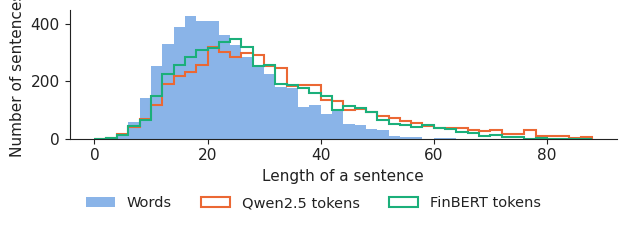

In [3]:
from transformers import AutoTokenizer
PB = pd.read_csv(DATA + 'financial_phrasebank.csv')
tq = AutoTokenizer.from_pretrained('Qwen/Qwen2.5-1.5B-Instruct')
tb = AutoTokenizer.from_pretrained('ProsusAI/finbert')
nw = PB.sentence.str.split().str.len().values
nq = np.array([len(tq.encode(s)) for s in PB.sentence])
nb = np.array([len(tb.encode(s, add_special_tokens=False)) for s in PB.sentence])
show('tok.qwen_per_word', 'Qwen tokens per word', round(float(nq.sum() / nw.sum()), 2))
show('tok.bert_per_word', 'WordPiece tokens per word', round(float(nb.sum() / nw.sum()), 2))
show('tok.qwen_mean', 'mean Qwen tokens per sentence', round(float(nq.mean()), 1))
fig, ax = plt.subplots(figsize=(6.4, 2.3))
bins = np.arange(0, 90, 2)
ax.hist(nw, bins=bins, color=PAL['data'], alpha=0.55, label='Words')
ax.hist(nq, bins=bins, histtype='step', lw=1.5, color=PAL['model'], label='Qwen2.5 tokens')
ax.hist(nb, bins=bins, histtype='step', lw=1.5, color=PAL['benchmark'], label='FinBERT tokens')
ax.set_xlabel('Length of a sentence')
ax.set_ylabel('Number of sentences')
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('tokens_per_sentence.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()